# 🚀 Practice Day 49

**📅 Date:** **2026-11-01**  
**📁 Category:** **Phase 2 · 테이블 병합(merge/join) (Round 4/5)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice combining multiple related tables with merge() to answer questions no single table can answer alone
  (여러 개의 연관된 테이블을 merge()로 연결해서, 테이블 하나만으로는 풀 수 없는 질문에 답하는 연습)
- Find which doctor drives the most revenue, which patient visits most often, and how average cost differs by doctor
  (어떤 의사가 매출을 가장 많이 견인하는지, 어떤 환자가 가장 자주 방문하는지, 의사별 평균 진료비는 어떻게 다른지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Meadowbrook Clinic — Patients, Doctors & Appointments (3 tables) / Meadowbrook Clinic — 환자·의사·진료예약 (3테이블)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** Three related tables from a small clinic. `patients` (65 rows: patient_id, patient_name), `doctors` (8 rows: doctor_id, doctor_name, specialty), and `appointments` (320 rows: appointment_id, patient_id → links to patients, doctor_id → links to doctors, appointment_date, cost). Costs are in USD. Every appointment links to exactly one patient and one doctor — clean, fully-linked keys with no missing values or duplicates.
(작은 클리닉의 연관된 3개 테이블입니다. `patients`(65명: patient_id, patient_name), `doctors`(8명: doctor_id, doctor_name, specialty), `appointments`(320건: appointment_id, patient_id(patients와 연결), doctor_id(doctors와 연결), appointment_date, cost). 진료비는 USD입니다. 모든 진료예약은 환자 1명과 의사 1명에게 연결되어 있고 결측치·중복 없이 깨끗합니다.)

## Dataset Preview

In [40]:
# Dataset Preview
import pandas as pd
import numpy as np
from IPython.display import display

np.random.seed(42)
rng = np.random.default_rng(42)

# --- patients ---
first_names = ['Sarah','James','Maria','David','Emily','Michael','Laura','Kevin','Anna','Brian',
               'Nicole','Daniel','Rachel','Peter','Grace','Tom','Julia','Mark','Susan','Chris',
               'Olivia','Ethan','Sophia','Lucas','Isabella','Mason','Ava','Logan','Mia','Noah']
last_names = ['Kim','Park','Lee','Smith','Johnson','Garcia','Brown','Davis','Wilson','Martinez',
              'Taylor','Clark','Lewis','Walker','Hall']

n_patients = 65
rng2 = np.random.default_rng(11)
patient_names = []
used = set()
while len(patient_names) < n_patients:
    name = f"{rng2.choice(first_names)} {rng2.choice(last_names)}"
    if name not in used:
        used.add(name)
        patient_names.append(name)

surname_map = {'Kim': 'Bennett', 'Park': 'Cooper', 'Lee': 'Hughes'}
patient_names = [
    f"{first} {surname_map.get(last, last)}"
    for first, last in (name.split(' ', 1) for name in patient_names)
]

patients = pd.DataFrame({
    'patient_id': [f'P{str(i).zfill(3)}' for i in range(1, n_patients + 1)],
    'patient_name': patient_names
})

# --- doctors ---
doctors_data = [
    ('Dr. Alina Novak', 'General Practice'),
    ('Dr. Ben Ortiz', 'General Practice'),
    ('Dr. Priya Nair', 'Pediatrics'),
    ('Dr. Samuel Chen', 'Pediatrics'),
    ('Dr. Elena Petrova', 'Cardiology'),
    ('Dr. Marcus Webb', 'Dermatology'),
    ('Dr. Fatima Haddad', 'Orthopedics'),
    ('Dr. Owen Fischer', 'Orthopedics'),
]
doctors = pd.DataFrame(doctors_data, columns=['doctor_name', 'specialty'])
doctors.insert(0, 'doctor_id', [f'D{str(i).zfill(2)}' for i in range(1, len(doctors) + 1)])

specialty_cost = {'General Practice': 45, 'Pediatrics': 55, 'Cardiology': 120,
                   'Dermatology': 80, 'Orthopedics': 95}  # USD

# --- appointments (some doctors/patients seen far more often than others) ---
n_appointments = 320
doctor_ids = doctors['doctor_id'].values
doctor_weight = rng.gamma(shape=2.0, scale=1.0, size=len(doctors))
doctor_p = doctor_weight / doctor_weight.sum()

patient_weight = rng.gamma(shape=1.6, scale=1.0, size=n_patients)
patient_p = patient_weight / patient_weight.sum()

appt_doctor = rng.choice(doctor_ids, size=n_appointments, p=doctor_p)
appt_patient = rng.choice(patients['patient_id'].values, size=n_appointments, p=patient_p)
appt_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 210, size=n_appointments), unit='D')

doc_specialty_map = dict(zip(doctors['doctor_id'], doctors['specialty']))
rows = []
for i in range(n_appointments):
    did = appt_doctor[i]
    spec = doc_specialty_map[did]
    cost_noise = rng.normal(1.0, 0.08)
    cost = int(round(specialty_cost[spec] * cost_noise))  # nearest USD
    rows.append({'appointment_id': f'A{str(i+1).zfill(4)}', 'patient_id': appt_patient[i],
                 'doctor_id': did, 'appointment_date': appt_dates[i], 'cost': cost})
appointments = pd.DataFrame(rows).sort_values('appointment_date').reset_index(drop=True)

print("Patients:")
display(patients.head())
print("\nDoctors:")
display(doctors)
print("\nAppointments:")
display(appointments.head())


Patients:


,patient_id,patient_name
0,P001,Emily Cooper
1,P002,Lucas Davis
2,P003,Mark Martinez
3,P004,Ethan Bennett
4,P005,Grace Hughes



Doctors:


,doctor_id,doctor_name,specialty
0,D01,Dr. Alina Novak,General Practice
1,D02,Dr. Ben Ortiz,General Practice
2,D03,Dr. Priya Nair,Pediatrics
3,D04,Dr. Samuel Chen,Pediatrics
4,D05,Dr. Elena Petrova,Cardiology
5,D06,Dr. Marcus Webb,Dermatology
6,D07,Dr. Fatima Haddad,Orthopedics
7,D08,Dr. Owen Fischer,Orthopedics



Appointments:


,appointment_id,patient_id,doctor_id,appointment_date,cost
0,A0042,P055,D02,2024-01-01,45
1,A0159,P037,D02,2024-01-01,46
2,A0227,P051,D08,2024-01-02,91
3,A0183,P048,D06,2024-01-03,88
4,A0102,P055,D07,2024-01-03,92


## Dataset Information

In [41]:
# Dataset Information
print("Patients:", patients.shape)
patients.info()
print("\nDoctors:", doctors.shape)
doctors.info()
print("\nAppointments:", appointments.shape)
appointments.info()

print("\n--- Describe: Patients ---")
display(patients.describe(include='all'))
print("\n--- Describe: Doctors ---")
display(doctors.describe(include='all'))
print("\n--- Describe: Appointments ---")
display(appointments.describe(include='all'))


Patients: (65, 2)
<class 'pandas.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   patient_id    65 non-null     str  
 1   patient_name  65 non-null     str  
dtypes: str(2)
memory usage: 1.1 KB

Doctors: (8, 3)
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   doctor_id    8 non-null      str  
 1   doctor_name  8 non-null      str  
 2   specialty    8 non-null      str  
dtypes: str(3)
memory usage: 324.0 bytes

Appointments: (320, 5)
<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   appointment_id    320 non-null    str           
 1   patient_id        320 non-null    str           
 2   doctor

,patient_id,patient_name
count,65,65
unique,65,65
top,P001,Emily Cooper
freq,1,1



--- Describe: Doctors ---


,doctor_id,doctor_name,specialty
count,8,8,8
unique,8,8,5
top,D01,Dr. Alina Novak,General Practice
freq,1,1,2



--- Describe: Appointments ---


,appointment_id,patient_id,doctor_id,appointment_date,cost
count,320,320,320,320,320.000000
unique,320,59,8,NaN,NaN
top,A0042,P061,D02,NaN,NaN
freq,1,15,57,NaN,NaN
mean,NaN,NaN,NaN,2024-04-11 22:39:00,76.271875
min,NaN,NaN,NaN,2024-01-01 00:00:00,36.000000
25%,NaN,NaN,NaN,2024-02-18 00:00:00,48.000000
50%,NaN,NaN,NaN,2024-04-09 12:00:00,79.500000
75%,NaN,NaN,NaN,2024-06-04 00:00:00,98.000000
max,NaN,NaN,NaN,2024-07-27 00:00:00,147.000000


---
# ❓ Business Questions

1. **(Analysis)** Which doctor generated the most total revenue, and which the least?
   (어떤 의사가 총 진료매출을 가장 많이/적게 냈는가?)
2. **(Analysis)** Which patient has visited the clinic the most times?
   (가장 많이 방문한 환자는 누구인가?)
3. **(Analysis)** Which doctor has the highest average cost per appointment, and which the lowest?
   (진료건당 평균 비용이 가장 높은/낮은 의사는?)
4. **(Visualization)** Compare total revenue across all doctors.
   (의사별 총 진료매출을 비교하면?)
5. **(Visualization)** Compare total revenue across all specialties.
   (진료과목별 총매출을 비교하면?)

---
# 🔍 Data Cleaning Check


In [42]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("===== patients =====")
print("Missing values")
print(patients.isnull().sum())
print("\nDuplicate rows:", patients.duplicated().sum())
print("\nDtypes")
print(patients.dtypes)
print("\nColumn names")
print(patients.columns.tolist())
obj_cols = patients.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(patients[obj_cols].nunique())
print()

print("===== doctors =====")
print("Missing values")
print(doctors.isnull().sum())
print("\nDuplicate rows:", doctors.duplicated().sum())
print("\nDtypes")
print(doctors.dtypes)
print("\nColumn names")
print(doctors.columns.tolist())
obj_cols = doctors.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(doctors[obj_cols].nunique())
print()

print("===== appointments =====")
print("Missing values")
print(appointments.isnull().sum())
print("\nDuplicate rows:", appointments.duplicated().sum())
print("\nDtypes")
print(appointments.dtypes)
print("\nColumn names")
print(appointments.columns.tolist())
obj_cols = appointments.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(appointments[obj_cols].nunique())
print()


===== patients =====
Missing values
patient_id      0
patient_name    0
dtype: int64

Duplicate rows: 0

Dtypes
patient_id      str
patient_name    str
dtype: object

Column names
['patient_id', 'patient_name']

Text columns — unique counts
patient_id      65
patient_name    65
dtype: int64

===== doctors =====
Missing values
doctor_id      0
doctor_name    0
specialty      0
dtype: int64

Duplicate rows: 0

Dtypes
doctor_id      str
doctor_name    str
specialty      str
dtype: object

Column names
['doctor_id', 'doctor_name', 'specialty']

Text columns — unique counts
doctor_id      8
doctor_name    8
specialty      5
dtype: int64

===== appointments =====
Missing values
appointment_id      0
patient_id          0
doctor_id           0
appointment_date    0
cost                0
dtype: int64

Duplicate rows: 0

Dtypes
appointment_id                 str
patient_id                     str
doctor_id                      str
appointment_date    datetime64[us]
cost                         

---
# 📊 Analysis

## Question 1

**Question:** Which doctor generated the most total revenue, and which the least? (총 진료매출 최고·최저 의사는?)

**Result:** Dr. Elena Petrova generated the most revenue at **$6,024**. Dr. Samuel Chen generated the least at **$1,095**. The gap is **$4,929**.  
(총진료매출 1위는 Dr. Elena Petrova $6,024, 맨 아래는 Dr. Samuel Chen $1,095. 차이는 $4,929)

**Insight:** Dr. Fatima Haddad is next at **$4,981**, which is **$1,043** below Dr. Elena Petrova. The eight doctors add to **$24,407**.  
(다음은 Dr. Fatima Haddad $4,981로 Dr. Elena Petrova보다 $1,043 적음. 의사 8명을 더하면 $24,407)

In [43]:
# Question 1: total revenue by doctor - needs merging appointments with doctors
merge_doctors = pd.merge(appointments, doctors, on='doctor_id', how='left')
merge_df = pd.merge(merge_doctors, patients, on='patient_id', how='left')

merge_df.groupby('doctor_name')['cost'].sum().sort_values(ascending=False)

doctor_name
Dr. Elena Petrova    6024
Dr. Fatima Haddad    4981
Dr. Owen Fischer     3971
Dr. Ben Ortiz        2562
Dr. Marcus Webb      2396
Dr. Alina Novak      1765
Dr. Priya Nair       1613
Dr. Samuel Chen      1095
Name: cost, dtype: int64

## Question 2

**Question:** Which patient has visited the clinic the most times? (가장 많이 방문한 환자는?)

**Result:** Patient **P061** visited the most, **15** times. Among the five printed IDs, **P026** is last at **11**. The gap is **4**.  
(방문 1위는 P061 15회. 출력된 다섯 아이디 중 맨 아래는 P026 11회. 차이는 4회)

**Insight:** **P003** is next at **14**, which is **1** below P061. **P051** has **13** and **P055** has **12**.  
(다음은 P003 14회로 P061보다 1회 적음. P051은 13회, P055는 12회)

In [44]:
# Question 2: which patient has visited the most times - needs merging appointments with patients
merge_df.groupby('patient_id')['appointment_id'].count().sort_values(ascending=False).head(5)

patient_id
P061    15
P003    14
P051    13
P055    12
P026    11
Name: appointment_id, dtype: int64

In [45]:
merge_df.loc[merge_df['patient_id'] == 'P061']['patient_name'].values[0]

'Rachel Cooper'

## Question 3

**Question:** Which doctor has the highest average cost per appointment, and which the lowest? (진료건당 평균 비용 최고·최저 의사는?)

**Result:** Dr. Elena Petrova has the highest average cost at **$118.12**. Dr. Ben Ortiz has the lowest at **$44.95**. The gap is **$73.17**.  
(건당 평균 비용 1위는 Dr. Elena Petrova $118.12, 맨 아래는 Dr. Ben Ortiz $44.95. 차이는 $73.17)

**Insight:** Dr. Fatima Haddad averages **$95.79**, which is **$22.33** below Dr. Elena Petrova. Dr. Ben Ortiz is fourth in total revenue at **$2,562** and last in average cost.  
(다음은 Dr. Fatima Haddad 평균 $95.79로 Dr. Elena Petrova보다 $22.33 적음. Dr. Ben Ortiz는 총매출 4위 $2,562이지만 평균은 맨 아래)

In [46]:
# Question 3: average cost per appointment by doctor
merge_df.groupby('doctor_name')['cost'].mean().sort_values(ascending=False)

doctor_name
Dr. Elena Petrova    118.117647
Dr. Fatima Haddad     95.788462
Dr. Owen Fischer      94.547619
Dr. Marcus Webb       79.866667
Dr. Priya Nair        55.620690
Dr. Samuel Chen       54.750000
Dr. Alina Novak       45.256410
Dr. Ben Ortiz         44.947368
Name: cost, dtype: float64

---
# 📈 Visualization

**Chart 1:** Bar chart — total revenue by doctor (막대그래프: 의사별 총매출)

*Interpretation:* The bars follow the doctor revenue table. Dr. Elena Petrova is **$6,024** and Dr. Samuel Chen is **$1,095**.  
(막대는 의사별 총매출 표 순서. Dr. Elena Petrova $6,024, Dr. Samuel Chen $1,095)

---

**Chart 2:** Bar chart — total revenue by specialty (막대그래프: 진료과목별 총매출)

*Interpretation:* Orthopedics is the longest bar at **$8,952**. Cardiology is **$6,024**, General Practice **$4,327**, Pediatrics **$2,708**, and Dermatology **$2,396**.  
(Orthopedics가 가장 김. $8,952. Cardiology $6,024, General Practice $4,327, Pediatrics $2,708, Dermatology $2,396)

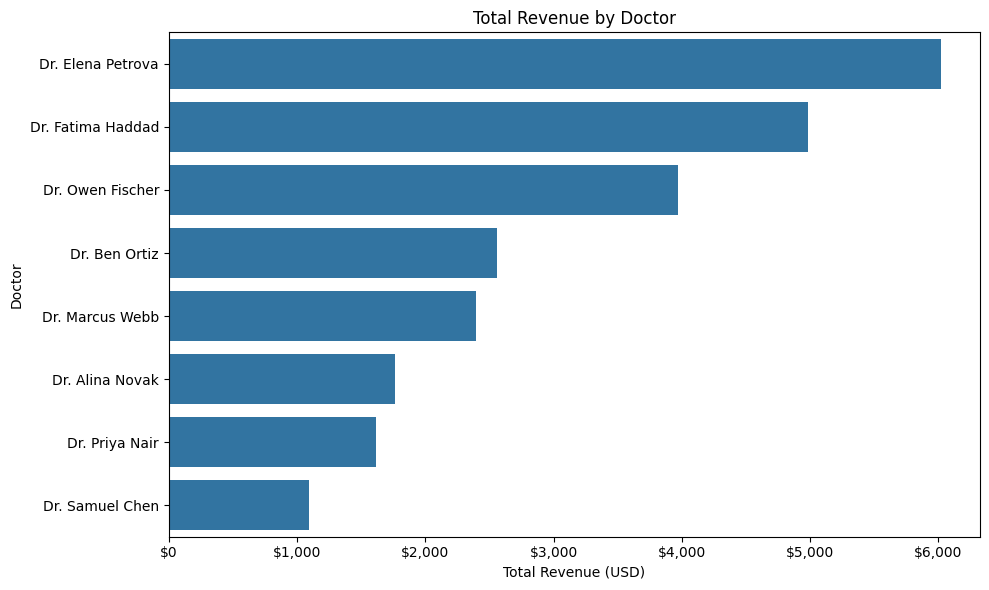

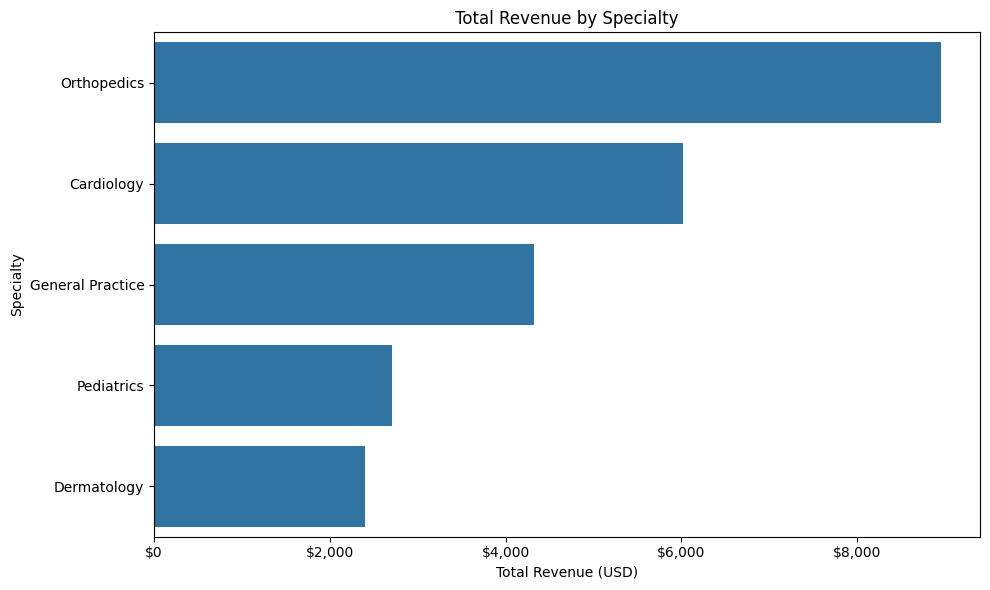

In [47]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: total revenue by doctor (bar)
revenue_by_doctor = merge_df.groupby('doctor_name')['cost'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=revenue_by_doctor.values, y=revenue_by_doctor.index, ax=ax, errorbar=None)
ax.set_title('Total Revenue by Doctor')
ax.set_xlabel('Total Revenue (USD)')
ax.set_ylabel('Doctor')
ax.xaxis.set_major_formatter('${x:,.0f}')
plt.tight_layout()

# Chart 2: total revenue by specialty (bar)
revenue_by_specialty = merge_df.groupby('specialty')['cost'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=revenue_by_specialty.values, y=revenue_by_specialty.index, ax=ax, errorbar=None)
ax.set_title('Total Revenue by Specialty')
ax.set_xlabel('Total Revenue (USD)')
ax.set_ylabel('Specialty')
ax.xaxis.set_major_formatter('${x:,.0f}')
plt.tight_layout()

---
# 💼 Business Insights
*What did I discover?*

- Dr. Elena Petrova leads doctor revenue at **$6,024**. Dr. Samuel Chen is last at **$1,095**.  
  (의사 총매출 1위는 Dr. Elena Petrova $6,024. Dr. Samuel Chen은 $1,095로 맨 아래)
- Patient **P061** has the most visits at **15**. **P003** is next at **14**.  
  (방문 1위는 P061 15회. 다음은 P003 14회)
- Dr. Elena Petrova also has the highest average at **$118.12**. Dr. Ben Ortiz is fourth in total revenue at **$2,562** and last in average at **$44.95**.  
  (Dr. Elena Petrova는 평균도 1위 $118.12. Dr. Ben Ortiz는 총매출 4위 $2,562이지만 평균은 맨 아래 $44.95)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Treat Orthopedics as the largest specialty total. It is **$8,952**, which is **$2,928** above Cardiology.  
   (Orthopedics를 과목 총매출 1위로 볼 것. $8,952로 Cardiology보다 $2,928 많음)
2. Cardiology revenue is one doctor. Dr. Elena Petrova's **$6,024** is **24.7%** of the **$24,407** total.  
   (Cardiology 매출은 의사 1명. Dr. Elena Petrova $6,024는 전체 $24,407의 24.7%)
3. Do not rank doctors by total revenue alone. Dr. Ben Ortiz's **$2,562** comes with the lowest average, **$44.95**.  
   (의사를 총매출만으로 순위를 매기지 않기. Dr. Ben Ortiz $2,562의 평균은 맨 아래 $44.95)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- The bar charts put revenue on x and the names on y, but the x-axis title said Doctor or Specialty and the y-axis title said Total Revenue.  
  (막대그래프는 x에 매출, y에 이름을 두었는데 x축 제목은 Doctor 또는 Specialty, y축 제목은 Total Revenue였음)
- The money axis had no USD format.  
  (돈 축에 USD 표시가 없었음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `pd.merge` on `doctor_id` and `patient_id` attaches the doctor and patient columns to each appointment.  
  (`doctor_id`와 `patient_id`로 `pd.merge`하면 각 진료예약에 의사·환자 열이 붙음)
- A descending `groupby` sum, plotted with `x` as the values and `y` as the index, keeps the table order on the bars.  
  (내림차순 `groupby` 합계를 `x`는 값, `y`는 인덱스로 그리면 표 순서가 막대 순서가 됨)
- Total revenue and average cost do not rank the doctors the same way. Dr. Ben Ortiz is **$2,562** in total and **$44.95** on average.  
  (총매출과 평균 비용은 의사 순위가 같지 않음. Dr. Ben Ortiz는 총매출 $2,562, 평균 $44.95)  

---
# 🧠 Reflection

**What was difficult?**  
Making the bars follow the sorted revenue instead of the name order.  
(막대를 이름순이 아니라 정렬된 매출 순서로 맞추는 것)

**Why?**  
`sns.barplot` on the appointment rows sorts the categories on its own. Passing `order` still needs the same grouped sum first.  
(예약 행을 그대로 `sns.barplot`에 넣으면 범주 순서는 따로 정렬됨. `order`를 넘겨도 먼저 같은 집계가 필요함)

**How did I solve it?**  
Grouped `cost` by doctor and by specialty, sorted descending, and plotted those series.  
(의사별·과목별로 `cost`를 묶어 내림차순으로 정렬한 뒤 그 Series를 그림)

**What would I do differently next time?**  
Check that the axis title sits on the revenue axis and includes USD.  
(축 제목이 매출 축에 있는지, USD가 붙었는지 확인하기)

---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
The merge and the three groupbys match the questions. Dr. Elena Petrova leads revenue at **$6,024** and average cost at **$118.12**. The money axis title was on the name axis.  
(merge와 groupby 세 개는 질문과 맞음. Dr. Elena Petrova가 총매출 $6,024, 평균 $118.12로 1위. 돈 축 제목이 이름 축에 있었음)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  
The joins were clean. The hard part was keeping the bar order equal to the sorted totals.  
(조인은 깨끗했음. 어려운 부분은 막대 순서를 정렬된 합계와 같게 맞추는 것이었음)

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 50 — SQL intermediate: JOIN, subquery, CASE WHEN (Round 4/5)  
  (JOIN, 서브쿼리, CASE WHEN으로 같은 질문을 다시 풀기)  